# Cohort Analysis — Monthly Customer Retention

Groups customers into monthly acquisition cohorts by first purchase, then tracks
what share of each cohort returns to buy again in later months. Complements the
RFM snapshot (which looks at a single point in time) with a retention view over time.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('cleaned_online_retail.csv', parse_dates=['InvoiceDate'])
df.shape

(779425, 9)

# Assign each customer to a monthly acquisition cohort

Cohort month = the month of each customer's first ever order.
Cohort index = number of months elapsed since that first order (0 = acquisition month).

In [2]:
df['InvoiceMonth'] = df['InvoiceDate'].dt.to_period('M')
df['CohortMonth'] = df.groupby('Customer ID')['InvoiceMonth'].transform('min')
df['CohortIndex'] = (
    (df['InvoiceMonth'].dt.year - df['CohortMonth'].dt.year) * 12
    + (df['InvoiceMonth'].dt.month - df['CohortMonth'].dt.month)
)

df[['Customer ID', 'InvoiceMonth', 'CohortMonth', 'CohortIndex']].head(10)

,Customer ID,InvoiceMonth,CohortMonth,CohortIndex
0,13085,2009-12,2009-12,0
1,13085,2009-12,2009-12,0
2,13085,2009-12,2009-12,0
3,13085,2009-12,2009-12,0
4,13085,2009-12,2009-12,0
5,13085,2009-12,2009-12,0
6,13085,2009-12,2009-12,0
7,13085,2009-12,2009-12,0
8,13085,2009-12,2009-12,0
9,13085,2009-12,2009-12,0


# Build the retention matrix

Count distinct active customers per (cohort, month-since-first-purchase), then divide
each row by that cohort's size to get the % of the cohort still buying.

In [3]:
cohort_counts = df.groupby(['CohortMonth', 'CohortIndex'])['Customer ID'].nunique().unstack()
retention = (cohort_counts.div(cohort_counts[0], axis=0) * 100).round(1)

print(f'Cohorts: {len(cohort_counts)}  |  Max months tracked: {int(cohort_counts.columns.max())}')
print(f'Total first-time customers: {int(cohort_counts[0].sum())}')
retention.iloc[:, :8]

Cohorts: 25  |  Max months tracked: 24
Total first-time customers: 5878


CohortIndex,0,1,2,3,4,5,6,7
CohortMonth,,,,,,,,
2009-12,100.0,35.3,33.4,42.5,38.0,35.9,37.7,34.2
2010-01,100.0,20.6,31.1,30.5,26.4,30.0,25.8,23.0
2010-02,100.0,23.8,22.5,29.1,24.6,20.1,19.3,28.6
2010-03,100.0,19.0,23.0,24.2,23.3,20.3,24.6,30.2
2010-04,100.0,19.4,19.4,16.3,18.4,22.4,27.6,26.2
2010-05,100.0,15.7,16.9,17.3,17.7,25.6,21.3,12.6
2010-06,100.0,17.4,18.9,20.4,23.0,28.5,12.6,8.9
2010-07,100.0,15.6,18.3,29.6,29.0,14.0,11.3,14.5
2010-08,100.0,20.4,29.6,32.1,17.3,11.7,9.9,12.3


# Retention heatmap

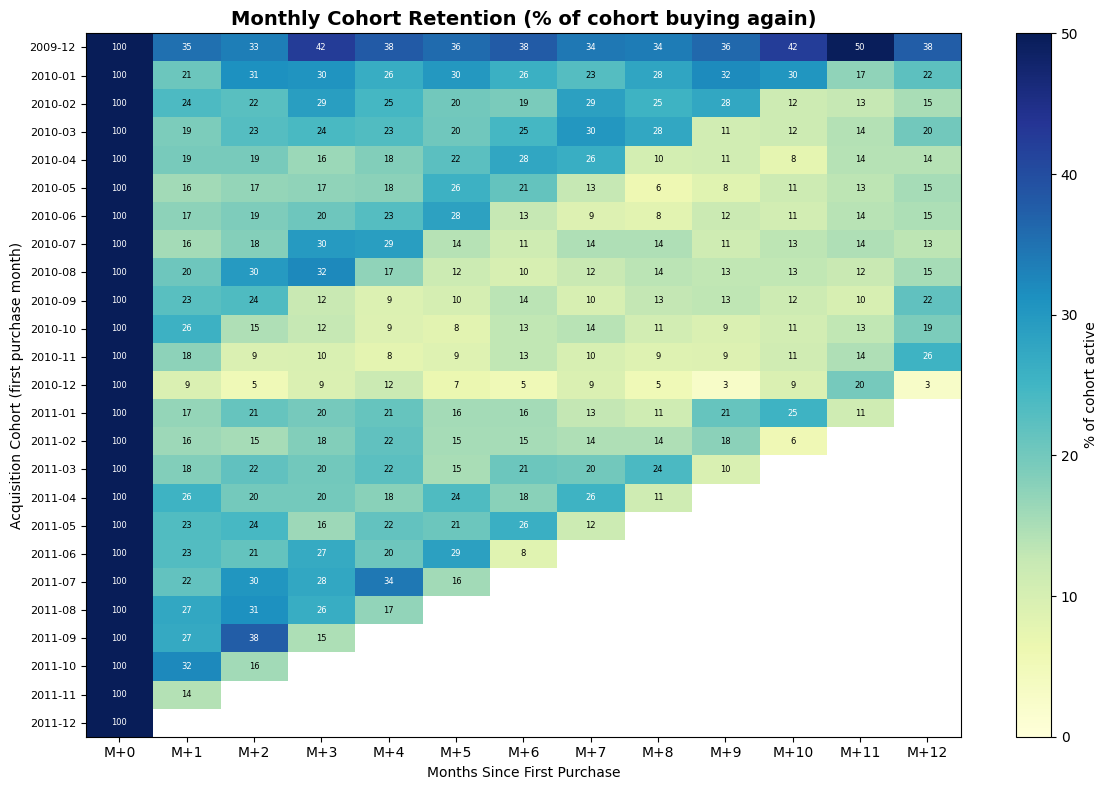

In [4]:
plot_data = retention.iloc[:, :13]

fig, ax = plt.subplots(figsize=(12, 8))
im = ax.imshow(plot_data.values, cmap='YlGnBu', aspect='auto', vmin=0, vmax=50)
ax.set_xticks(range(plot_data.shape[1]))
ax.set_xticklabels([f'M+{i}' for i in plot_data.columns])
ax.set_yticks(range(plot_data.shape[0]))
ax.set_yticklabels([str(p) for p in plot_data.index], fontsize=8)
ax.set_xlabel('Months Since First Purchase')
ax.set_ylabel('Acquisition Cohort (first purchase month)')
ax.set_title('Monthly Cohort Retention (% of cohort buying again)', fontsize=14, fontweight='bold')

for i in range(plot_data.shape[0]):
    for j in range(plot_data.shape[1]):
        v = plot_data.values[i, j]
        if not pd.isna(v):
            ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=6,
                    color='white' if v > 25 else 'black')

plt.colorbar(im, label='% of cohort active')
plt.tight_layout()
plt.savefig('chart5_cohort_retention.png', dpi=150)
plt.show()

# Headline retention numbers

Averages are taken across all cohorts that have enough history to have that value.

In [5]:
for k in [1, 2, 3, 6, 9, 11]:
    print(f'Month-{k:>2} retention  |  mean {retention[k].mean():.1f}%   median {retention[k].median():.1f}%')

print()
print('Cohort sizes (first-time customers):')
print(cohort_counts[0].astype(int).to_string())

Month- 1 retention  |  mean 21.2%   median 20.5%
Month- 2 retention  |  mean 21.9%   median 21.3%
Month- 3 retention  |  mean 21.6%   median 20.0%
Month- 6 retention  |  mean 17.8%   median 15.5%
Month- 9 retention  |  mean 15.3%   median 11.6%
Month-11 retention  |  mean 16.4%   median 13.8%

Cohort sizes (first-time customers):
CohortMonth
2009-12    955
2010-01    383
2010-02    374
2010-03    443
2010-04    294
2010-05    254
2010-06    270
2010-07    186
2010-08    162
2010-09    243
2010-10    377
2010-11    325
2010-12     76
2011-01     71
2011-02    124
2011-03    179
2011-04    106
2011-05    111
2011-06    108
2011-07    102
2011-08    106
2011-09    189
2011-10    221
2011-11    191
2011-12     28
Freq: M


# Revenue retention

Same idea, but measuring the share of each cohort's month-0 spend that returns
in later months. Answers whether repeat buyers spend at similar levels.

In [6]:
rev = df.groupby(['CohortMonth', 'CohortIndex'])['TotalPrice'].sum().unstack()
rev_ret = (rev.div(rev[0], axis=0) * 100).round(1)

for k in [1, 3, 6, 11]:
    print(f'Month-{k:>2} REVENUE retention (mean): {rev_ret[k].mean():.1f}%')

rev_ret.iloc[:, :8]

Month- 1 REVENUE retention (mean): 20.9%
Month- 3 REVENUE retention (mean): 26.2%
Month- 6 REVENUE retention (mean): 18.0%
Month-11 REVENUE retention (mean): 20.6%


CohortIndex,0,1,2,3,4,5,6,7
CohortMonth,,,,,,,,
2009-12,100.0,57.8,43.3,55.4,44.8,44.6,44.2,45.8
2010-01,100.0,24.2,31.6,35.6,36.3,37.7,32.3,29.8
2010-02,100.0,19.6,32.2,31.4,25.9,23.3,23.6,30.1
2010-03,100.0,21.2,22.1,27.5,21.4,23.8,27.9,34.6
2010-04,100.0,15.2,16.6,24.2,17.9,24.8,28.3,26.3
2010-05,100.0,12.3,12.7,11.5,15.3,28.2,21.0,8.2
2010-06,100.0,12.2,17.2,19.7,26.7,36.9,12.1,13.2
2010-07,100.0,11.2,18.2,33.2,38.2,12.0,12.1,13.9
2010-08,100.0,22.7,38.0,38.6,23.4,8.9,8.7,12.0


# Key takeaways

- **Only ~21% of a cohort buys again the very next month** — the drop-off happens
  immediately after the first purchase, not gradually.
- **Retention then plateaus around 15–22%** out to month 11, so customers who
  survive the first month tend to stick. The problem is the first-month handoff.
- **Holiday cohorts retain best**: the Dec 2009 cohort (955 customers, the largest)
  held 35% at month 1 vs ~15–19% for mid-2010 cohorts — gift-driven buyers
  behave differently from habitual buyers.
- **Revenue retention (~21% at M1) tracks customer retention closely**, so the
  repeat spenders spend at comparable levels — fixing first-month retention is
  the single highest-leverage revenue lever.
- This reinforces the RFM finding: protect Champions/Loyal (83.7% of revenue)
  and run win-back on the 353 At Risk customers (£1.09M).